# CSC 4110 Machine Learning: task notebook


| Field | Fill in |
|---|---|
| Task | 2.2 Transformation, EDA and split |
| Owner (name) | Collins Kipkorir |
| Registration number | COM/0021/23 |
| Group | G04 |
| Dataset | Credit Risk Dataset |
| Date started | 25 November 2026 |


**Rules**
- Save this file in your group folder as `G<No>_U<task>_<short name>.ipynb`, exactly as shown under **Save as** in your group's paper, e.g. `G01_U2.1_cleaning.ipynb`.
- One Markdown heading per part, then its code cells. Comment every code cell.
- Use the exact variable and file names in **Graded evidence** of your task, and `random_state=42` everywhere.
- Reviewers add a cell headed **Review by <Name>** in the Reviews section. They never edit the owner's cells.

In [1]:
# Setup: set your group and task, connect Google Drive, and work inside the group folder
GROUP = "G04"        # your group, two digits
UNIT = "2.2"         # your task number: 2.1, 2.2, 3.1, 3.2, 4, 5, 6, 7, 8, 9.1, 9.2 or 9.3
RANDOM_STATE = 42    # use this everywhere so the grader gets the same numbers

import os
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as e:
    print("Drive not mounted here:", e)   # normal when the grader runs this notebook

BASE = f"/content/drive/MyDrive/CSC4110_{GROUP}"
for sub in ["data", "notebooks", "models", "outputs", "app", "report", "tests"]:
    os.makedirs(f"{BASE}/{sub}", exist_ok=True)
os.chdir(BASE)   # every path below is relative to the group folder
print("Working in", os.getcwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Working in /content/drive/.shortcut-targets-by-id/1Hfur0Lf8z0gktOkV4oQdkhdGubaALOUm/CSC4110_G04


In [2]:
# Libraries used in most tasks, and a helper that saves every chart to outputs/
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def save_fig(name):
    """Save the current chart as outputs/<name>.png, then show it."""
    path = f"outputs/{name}.png"
    plt.tight_layout()
    plt.savefig(path, dpi=120)
    print("Saved", path)
    plt.show()

## Load the data

- Task 2.1 loads the original Kaggle file.
- Task 2.2 loads `data/stage1_<dataset>.csv`.
- Every other task loads `data/clean_<dataset>.csv`.

In [3]:

# Task 2.2: Load the cleaned dataset

# Use the dataset prepared in Task 2.1
DATA_FILE = "data/stage1_credit.csv"

# Load the CSV file
df = pd.read_csv(DATA_FILE)

# Display the number of rows and columns
print("Dataset shape:", df.shape)

# Show the first five loan records
display(df.head())

# Display the column names
print("Column names:")
print(df.columns.tolist())


Dataset shape: (32409, 13)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,rate_imputed
0,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2,0
1,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3,0
2,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2,0
3,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4,0
4,21,9900,OWN,2.0,VENTURE,A,2500,7.14,1,0.25,N,2,0


Column names:
['person_age', 'person_income', 'person_home_ownership', 'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt', 'loan_int_rate', 'loan_status', 'loan_percent_income', 'cb_person_default_on_file', 'cb_person_cred_hist_length', 'rate_imputed']



## Task 2.2(a): Data Transformation

This section converts categorical information into numerical features and creates age bands and logarithmic income for machine learning.


In [4]:

# Task 2.2(a): Transform the cleaned loan data

# Work on a copy of Festus's dataset
df_clean = df.copy(deep=True)

# 1. Convert loan grades A-G into numbers 0-6
grade_map = {
    "A": 0, "B": 1, "C": 2, "D": 3,
    "E": 4, "F": 5, "G": 6
}

df_clean["loan_grade"] = df_clean["loan_grade"].map(grade_map)

# 2. Convert previous default history into numbers
df_clean["cb_person_default_on_file"] = (
    df_clean["cb_person_default_on_file"].map({"Y": 1, "N": 0})
)

# 3. One-hot encode home ownership and loan intent
# Keep original columns for later fairness analysis
encoded = pd.get_dummies(
    df_clean[["person_home_ownership", "loan_intent"]],
    dtype=int
)

df_clean = pd.concat([df_clean, encoded], axis=1)

# 4. Create age groups
df_clean["age_band"] = pd.cut(
    df_clean["person_age"],
    bins=[-np.inf, 25, 35, 45, np.inf],
    labels=["under 25", "25-34", "35-44", "45 and over"],
    right=False
)

# 5. Create logarithmic income
if (df_clean["person_income"] <= 0).any():
    raise ValueError("Income must be positive for log transformation")

df_clean["log_income"] = np.log(df_clean["person_income"])

# 6. Save the transformed dataset
df_clean.to_csv("data/clean_credit.csv", index=False)

# 7. Display the results
print("Transformed dataset shape:", df_clean.shape)
print("Original rows:", len(df))
print("Transformed rows:", len(df_clean))

print("\nLoan grade encoding:")
print(df_clean["loan_grade"].value_counts().sort_index())

print("\nAge bands:")
print(df_clean["age_band"].value_counts())

print("\nFirst five transformed records:")
display(df_clean.head())

print("\nSaved as data/clean_credit.csv")


Transformed dataset shape: (32409, 25)
Original rows: 32409
Transformed rows: 32409

Loan grade encoding:
loan_grade
0    10702
1    10384
2     6436
3     3619
4      963
5      241
6       64
Name: count, dtype: int64

Age bands:
age_band
25-34          16115
under 25       12220
35-44           3320
45 and over      754
Name: count, dtype: int64

First five transformed records:


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,...,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_DEBTCONSOLIDATION,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE,age_band,log_income
0,21,9600,OWN,5.0,EDUCATION,1,1000,11.14,0,0.10,...,1,0,0,1,0,0,0,0,under 25,9.169518
1,25,9600,MORTGAGE,1.0,MEDICAL,2,5500,12.87,1,0.57,...,0,0,0,0,0,1,0,0,25-34,9.169518
2,23,65500,RENT,4.0,MEDICAL,2,35000,15.23,1,0.53,...,0,1,0,0,0,1,0,0,under 25,11.089805
3,24,54400,RENT,8.0,MEDICAL,2,35000,14.27,1,0.55,...,0,1,0,0,0,1,0,0,under 25,10.904119
4,21,9900,OWN,2.0,VENTURE,0,2500,7.14,1,0.25,...,1,0,0,0,0,0,0,1,under 25,9.200290



Saved as data/clean_credit.csv



### Exam Skill: Ordinal and One-Hot Encoding

Loan grade is ordinal because its categories have a meaningful order from A to G. Grade A represents a better credit grade than B, and the grades continue in order. Therefore, I encoded grades A to G using the numbers 0 to 6.

Loan intent is not ordinal because categories such as EDUCATION, MEDICAL and PERSONAL do not have a natural ranking. I used one-hot encoding to create separate numerical columns for the different loan purposes.

I also one-hot encoded home ownership, created age bands and calculated logarithmic income to prepare the dataset for machine learning.


## Part a) <title of the part, copied from the practical>

Write a python code to:
1. <step 1>
2. <step 2>


## Task 2.2(b): Exploratory Data Analysis

This section uses five charts to explore loan interest rates, borrower characteristics, loan defaults and relationships between numerical variables.


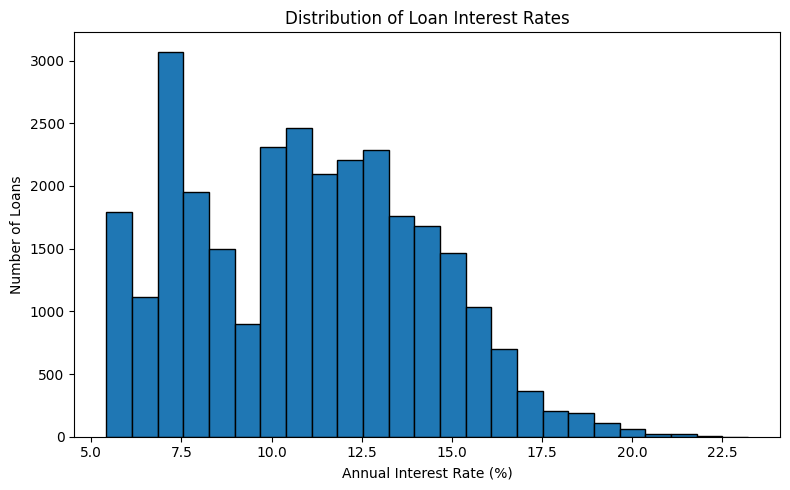

Histogram saved as outputs/hist_target.png
Loans included: 29315


In [5]:

# Task 2.2(b): Chart 1 - Histogram of interest rates

# Use only originally observed interest rates
observed_rates = df_clean.loc[
    df_clean["rate_imputed"] == 0,
    "loan_int_rate"
]

# Create the histogram
plt.figure(figsize=(8, 5))

plt.hist(
    observed_rates,
    bins=25,
    edgecolor="black"
)

# Add a title and labels
plt.title("Distribution of Loan Interest Rates")
plt.xlabel("Annual Interest Rate (%)")
plt.ylabel("Number of Loans")

# Save the chart
plt.tight_layout()
plt.savefig("outputs/hist_target.png", dpi=150)

# Show the chart
plt.show()

print("Histogram saved as outputs/hist_target.png")
print("Loans included:", len(observed_rates))


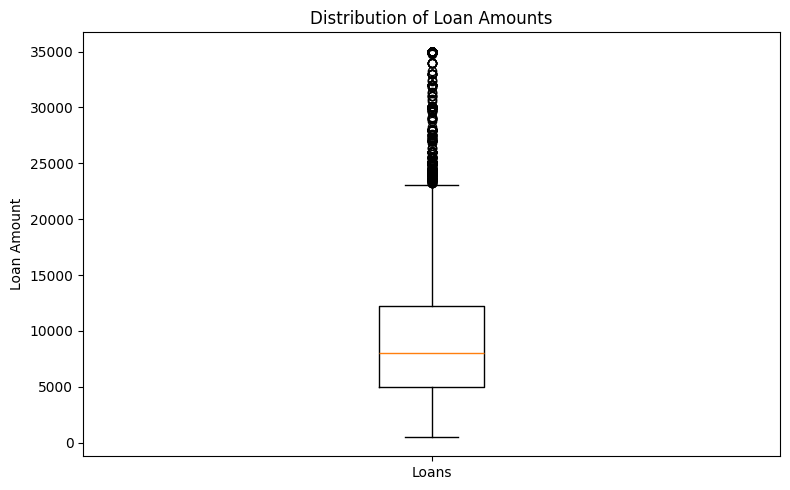

Box plot saved as outputs/box_feature.png


In [6]:

# Task 2.2(b): Chart 2 - Box plot of loan amounts

# Create a chart
plt.figure(figsize=(8, 5))

# Draw the box plot using loan amounts
plt.boxplot(df_clean["loan_amnt"].dropna())

# Add the chart title and labels
plt.title("Distribution of Loan Amounts")
plt.ylabel("Loan Amount")
plt.xticks([1], ["Loans"])

# Save the chart to the outputs folder
plt.tight_layout()
plt.savefig("outputs/box_feature.png", dpi=150)

# Display the chart
plt.show()

print("Box plot saved as outputs/box_feature.png")


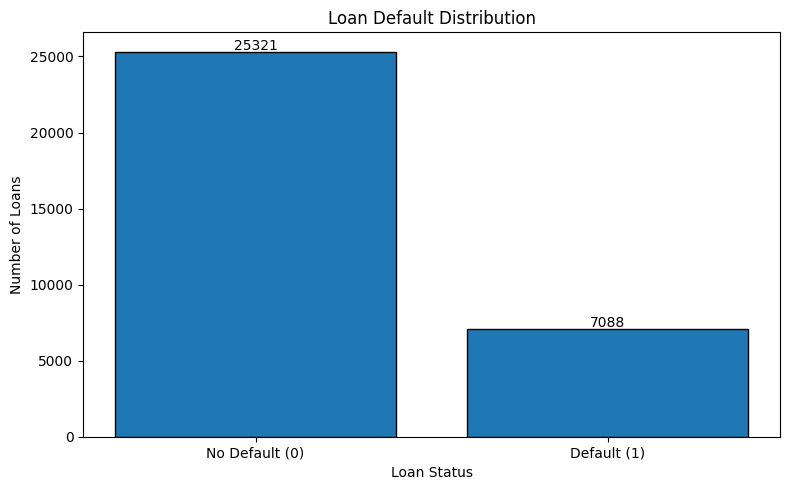

Loan status counts:
loan_status
0    25321
1     7088
Name: count, dtype: int64

Loan status percentages:
loan_status
0    78.13
1    21.87
Name: count, dtype: float64

Saved as outputs/bar_class.png


In [7]:

# Task 2.2(b): Chart 3 - Bar chart of loan defaults

# Count loans in each classification category
class_counts = df_clean["loan_status"].value_counts()
class_counts = class_counts.reindex([0, 1], fill_value=0)

# Create the bar chart
plt.figure(figsize=(8, 5))

plt.bar(
    ["No Default (0)", "Default (1)"],
    class_counts.values,
    edgecolor="black"
)

# Add chart title and axis labels
plt.title("Loan Default Distribution")
plt.xlabel("Loan Status")
plt.ylabel("Number of Loans")

# Display the number above each bar
for i, count in enumerate(class_counts.values):
    plt.text(i, count + 100, str(count), ha="center")

# Save the bar chart
plt.tight_layout()
plt.savefig("outputs/bar_class.png", dpi=150)

# Display the chart
plt.show()

# Print the counts and percentages
print("Loan status counts:")
print(class_counts)

print("\nLoan status percentages:")
print((class_counts / class_counts.sum() * 100).round(2))

print("\nSaved as outputs/bar_class.png")


Correlations with interest rate:
person_age                    0.011129
person_income                -0.018078
person_emp_length            -0.055771
loan_amnt                     0.146926
loan_percent_income           0.120111
cb_person_cred_hist_length    0.015855
log_income                   -0.028116
Name: loan_int_rate, dtype: float64

Best numeric predictor: loan_amnt
Correlation: 0.1469


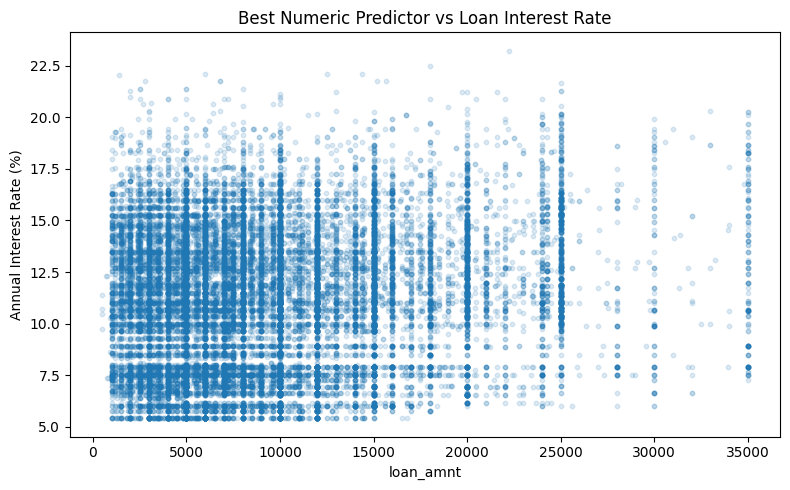


Saved as outputs/scatter_best.png


In [8]:

# Task 2.2(b): Chart 4 - Scatter plot of the best numeric predictor

# Use only loans with originally observed interest rates
reg_data = df_clean[df_clean["rate_imputed"] == 0].copy()

# Numerical features allowed for interest-rate prediction
numeric_features = [
    "person_age",
    "person_income",
    "person_emp_length",
    "loan_amnt",
    "loan_percent_income",
    "cb_person_cred_hist_length",
    "log_income"
]

# Calculate correlations with the interest rate
correlations = reg_data[
    numeric_features + ["loan_int_rate"]
].corr()["loan_int_rate"].drop("loan_int_rate")

# Find the strongest relationship by absolute correlation
best_feature = correlations.abs().idxmax()
best_correlation = correlations[best_feature]

print("Correlations with interest rate:")
print(correlations)

print("\nBest numeric predictor:", best_feature)
print("Correlation:", round(best_correlation, 4))

# Create the scatter plot
plt.figure(figsize=(8, 5))

plt.scatter(
    reg_data[best_feature],
    reg_data["loan_int_rate"],
    alpha=0.15,
    s=10
)

# Add title and axis labels
plt.title("Best Numeric Predictor vs Loan Interest Rate")
plt.xlabel(best_feature)
plt.ylabel("Annual Interest Rate (%)")

# Save and show the chart
plt.tight_layout()
plt.savefig("outputs/scatter_best.png", dpi=150)
plt.show()

print("\nSaved as outputs/scatter_best.png")


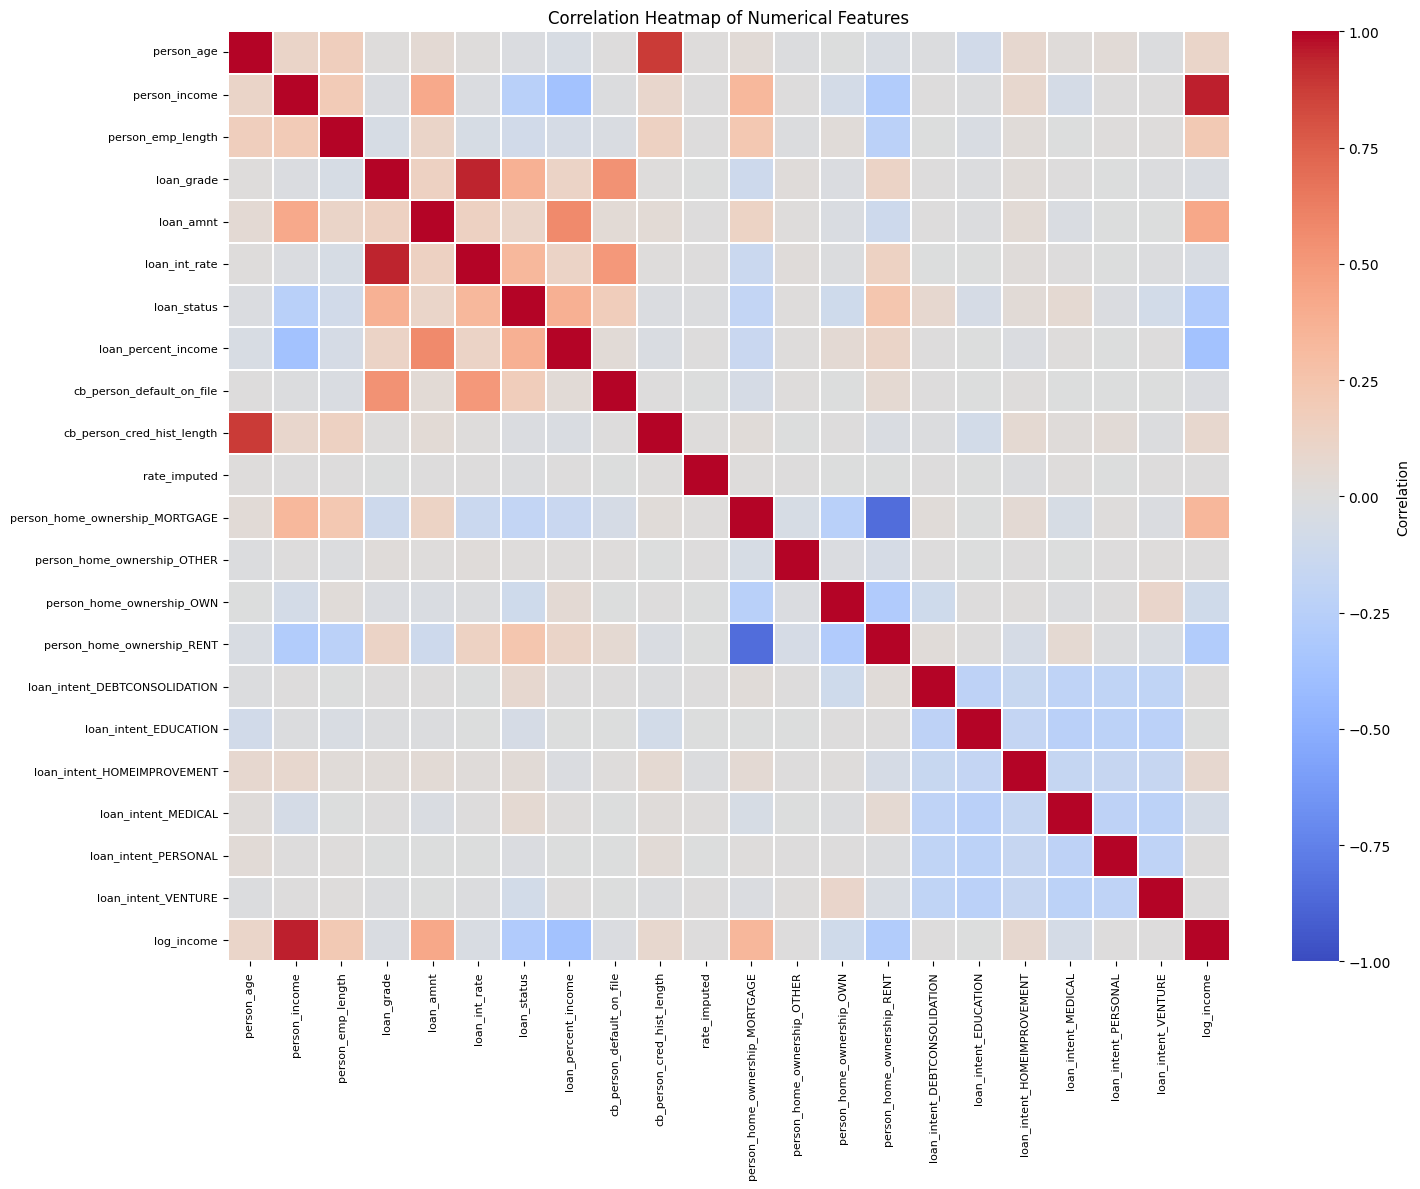

Heatmap saved as outputs/corr_heatmap.png
Number of numerical columns: 22


In [9]:

# Task 2.2(b): Chart 5 - Correlation Heatmap

# Import Seaborn for creating the heatmap
import seaborn as sns

# Select all numerical columns
numeric_data = df_clean.select_dtypes(include="number")

# Calculate the correlation matrix
corr_matrix = numeric_data.corr()

# Create the heatmap
plt.figure(figsize=(15, 12))

sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.2,
    cbar_kws={"label": "Correlation"}
)

# Add the chart title
plt.title("Correlation Heatmap of Numerical Features")

# Make the labels easier to read
plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)

# Save the heatmap
plt.tight_layout()
plt.savefig("outputs/corr_heatmap.png", dpi=150)

# Display the heatmap
plt.show()

print("Heatmap saved as outputs/corr_heatmap.png")
print("Number of numerical columns:", numeric_data.shape[1])



## Task 2.2(c): Min-Max Scaling and Standard Scaling

This section demonstrates how to transform borrower income using Min-Max scaling and Standard scaling.


In [10]:

# Task 2.2(c): Demonstrate two scaling methods

# Import the scaling tools
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Select the income column
income_data = df_clean[["person_income"]]

# Create the two scalers for demonstration
demo_minmax = MinMaxScaler()
demo_standard = StandardScaler()

# Apply Min-Max scaling
income_minmax = demo_minmax.fit_transform(income_data)

# Apply Standard scaling
income_standard = demo_standard.fit_transform(income_data)

# Put the three versions side by side
scaling_comparison = pd.DataFrame({
    "Original Income": df_clean["person_income"].values,
    "Min-Max Scaled": income_minmax.ravel(),
    "Standard Scaled": income_standard.ravel()
})

# Display the first five rows
print("FIRST FIVE INCOME VALUES:")
display(scaling_comparison.head().round(4))

print("Min-Max range:",
      round(income_minmax.min(), 4),
      "to",
      round(income_minmax.max(), 4))


FIRST FIVE INCOME VALUES:


,Original Income,Min-Max Scaled,Standard Scaled
0,9600,0.0411,-1.6612
1,9600,0.0411,-1.6612
2,65500,0.4514,0.0966
3,54400,0.3699,-0.2524
4,9900,0.0433,-1.6518


Min-Max range: 0.0 to 1.0



### Exam Skill: When to Use Each Scaling Method

Min-Max scaling transforms numerical values into a range between 0 and 1. It is useful for algorithms that depend on distances, such as K-nearest neighbours, when a fixed scale is helpful.

Standard scaling transforms values by subtracting the mean and dividing by the standard deviation. It is useful for algorithms such as linear models, support vector machines and neural networks.

For actual model training, the scaler must be fitted using the training dataset only. The test dataset must be transformed using the same fitted scaler to prevent data leakage.



## Task 2.2(d): Train-Test Split Without Data Leakage

This section prepares the interest-rate regression data, removes inappropriate features, splits the records into training and testing sets, and fits the scaler using training data only.


In [11]:

# Task 2.2(d): Prepare and split regression data

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Use only loans with originally observed interest rates
regression_data = df_clean[
    df_clean["rate_imputed"] == 0
].copy()

# Set the regression target
y = regression_data["loan_int_rate"]

# Select numerical features and remove leakage columns
X = regression_data.select_dtypes(include="number").drop(
    columns=[
        "loan_int_rate",
        "loan_grade",
        "loan_status",
        "rate_imputed"
    ]
)

# Split the data: 80% training and 20% testing
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Create a scaler and fit it on training data ONLY
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_raw)

# Apply the same scaler to testing data
X_test_scaled = scaler.transform(X_test_raw)

# Preserve column names for later modelling tasks
X_train = pd.DataFrame(
    X_train_scaled,
    columns=X.columns,
    index=X_train_raw.index
)

X_test = pd.DataFrame(
    X_test_scaled,
    columns=X.columns,
    index=X_test_raw.index
)

# Display the results
print("Original regression records:", len(regression_data))
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Number of features:", X_train.shape[1])

print("\nX_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

print("\nFeatures used:")
print(X_train.columns.tolist())

# Verify that leakage features are excluded
assert "loan_grade" not in X_train.columns
assert "loan_status" not in X_train.columns
assert "rate_imputed" not in X_train.columns

print("\nSplit completed successfully without target leakage.")


Original regression records: 29315
Training rows: 23452
Testing rows: 5863
Number of features: 18

X_train shape: (23452, 18)
X_test shape: (5863, 18)
y_train shape: (23452,)
y_test shape: (5863,)

Features used:
['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_percent_income', 'cb_person_default_on_file', 'cb_person_cred_hist_length', 'person_home_ownership_MORTGAGE', 'person_home_ownership_OTHER', 'person_home_ownership_OWN', 'person_home_ownership_RENT', 'loan_intent_DEBTCONSOLIDATION', 'loan_intent_EDUCATION', 'loan_intent_HOMEIMPROVEMENT', 'loan_intent_MEDICAL', 'loan_intent_PERSONAL', 'loan_intent_VENTURE', 'log_income']

Split completed successfully without target leakage.


In [12]:
# a1. <what this cell does>


## Part b) <title of the part, copied from the practical>

Write a python code to:
1. <step 1>
2. <step 2>

In [13]:
# b1. <what this cell does>


## Part c) <title of the part, copied from the practical>

Write a python code to:
1. <step 1>
2. <step 2>

In [14]:
# c1. <what this cell does>



## Task 2.2: Written Answer — EDA and Data Splitting

The dataset contained 32,409 loans, of which 25,321 (78.13%) did not default and 7,088 (21.87%) defaulted, showing that the classes are imbalanced.

The interest-rate histogram showed that most observed annual interest rates were approximately between 7% and 15%.

The loan-amount box plot showed a median loan amount of approximately 8,000, with some unusually large loans reaching 35,000.

The strongest numerical predictor among those tested was `loan_amnt`, which had a weak positive correlation of 0.1469 with the interest rate.

For regression, I excluded the 3,094 records with imputed interest rates and split the remaining 29,315 records into 23,452 training and 5,863 testing records; I fitted the scaler on training data only because fitting it on the test data would cause data leakage and make the model evaluation less reliable.

## Reviews

### Review by <Name>
A check, an improvement or a question.

## Evidence checklist (tick before you submit)

- [ ] Runtime → Restart session and run all: no errors
- [ ] The basic check below shows no missing names or files
- [ ] The written answer is complete and quotes my numbers
- [ ] The self-check cell from Moodle passes
- [ ] File → Save, and File → Save a copy in GitHub

In [15]:
# Basic check: are the required variables and files there? (names and files only;
# the self-check cell on Moodle also tests the values)
import glob
REQUIRED = {
    "2.1": (["df_raw", "df_stage1", "outlier_col", "lower", "upper"], ["data/stage1_*.csv"]),
    "2.2": (["df_clean", "X_train", "X_test", "y_train", "y_test", "scaler"],
            ["data/clean_*.csv", "outputs/hist_target.png", "outputs/box_feature.png",
             "outputs/bar_class.png", "outputs/scatter_best.png", "outputs/corr_heatmap.png"]),
    "3.1": (["lr_simple", "lr_multi", "metrics_multi", "b0_gd", "b1_gd", "cost_history"],
            ["outputs/simple_fit.png", "outputs/actual_vs_pred.png", "outputs/gd_cost.png"]),
    "3.2": (["poly_results", "ridge_results", "lasso_results", "results_reg"],
            ["outputs/under_over_fit.png", "outputs/regression_comparison.png"]),
    "4":   (["y_train", "y_test", "log_reg", "cm", "results_clf"], ["outputs/confusion_matrix.png"]),
    "5":   (["pipe", "cv_scores", "grid", "test_score", "threshold_results"],
            ["outputs/learning_curve.png", "outputs/validation_curve.png"]),
    "6":   (["tree3", "ig_root", "depth_results", "results_trees", "importances"],
            ["outputs/tree_depth3.png", "outputs/depth_curve.png", "outputs/feature_importance.png"]),
    "7":   (["inertias", "sil_scores", "best_k", "pca", "dbscan_labels", "Q", "success_rates"],
            ["outputs/elbow.png", "outputs/pca_clusters.png", "outputs/success_rate.png"]),
    "8":   (["w_and", "b_and", "mlp_results", "best_mlp", "activation_results", "mlp_reg_rmse"], ["outputs/loss_curve.png"]),
    "9.1": (["final_pipe"], ["models/*_model.joblib", "app/app.py", "app/requirements.txt",
                             "outputs/app_screenshot.png"]),
    "9.2": (["fairness_table", "flagged"], ["outputs/fairness.csv", "outputs/fairness.png",
                                            "report/model_card.md"]),
    "9.3": ([], ["tests/smoke_test.py", "README.md"]),
}
names, files = REQUIRED[UNIT]
missing_names = [n for n in names if n not in globals()]
missing_files = [f for f in files if not glob.glob(f)]
print(f"Task {UNIT}")
print("Missing variables:", missing_names or "none")
print("Missing files:", missing_files or "none")
print("PASS" if not (missing_names or missing_files) else "FIX the items above before you submit")

Task 2.2
Missing variables: none
Missing files: none
PASS


## Self-check

Paste the self-check cell for your task from its Moodle assignment below, then run it.

In [16]:
# Paste the self-check cell from Moodle here
